In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import butter, filtfilt

In [14]:
from google.colab import files
uploaded = files.upload()

Saving EMG2.csv to EMG2 (2).csv


In [15]:
df = pd.read_csv('EMG2.csv')
time = df.iloc[:,0].values
emg  = df.iloc[:,1].values


In [16]:
# Resample
from scipy.interpolate import interp1d
fs = 1000
t_uniform = np.arange(time.min(), time.max(), 1/fs)
interp = interp1d(time, emg, kind='linear')
emg_uniform = interp(t_uniform)

In [17]:
# Filter
def bandpass(signal, low, high, fs):
    nyq = 0.5 * fs
    b, a = butter(4, [low/nyq, high/nyq], btype='band')
    return filtfilt(b, a, signal)

emg_filtered = bandpass(emg_uniform, 20, 450, fs)

In [18]:
# Rectify
emg_rectified = np.abs(emg_filtered)

# Envelope
window = int(0.05 * fs)
envelope = np.convolve(emg_rectified,
                       np.ones(window)/window,
                       mode='same')


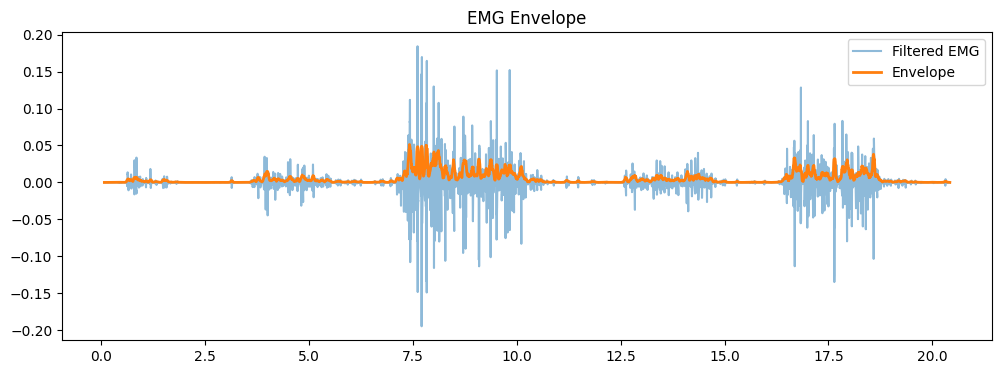

In [19]:
# Plot
plt.figure(figsize=(12,4))
plt.plot(t_uniform, emg_filtered, alpha=0.5, label='Filtered EMG')
plt.plot(t_uniform, envelope, linewidth=2, label='Envelope')
plt.legend()
plt.title("EMG Envelope")
plt.show()

In [20]:
from scipy.signal import welch
import numpy as np

# ---- FIX: define time ----
time_common = np.linspace(0, 60, len(emg_r))   # adjust duration if needed

# Sampling frequency

# Apply resampling
ecg_r = resample(ecg_sig, time_ecg, time_common)
emg_r = resample(emg_sig, time_emg, time_common)
fs = len(time_common) / 60
print("Sampling Frequency:", fs)

# ---- SNR function ----
def compute_snr(signal, fs, band_low, band_high):
    f, Pxx = welch(signal, fs, nperseg=256)

    signal_power = np.sum(Pxx[(f >= band_low) & (f <= band_high)])
    noise_power = np.sum(Pxx) - signal_power

    if noise_power == 0:
        return np.inf

    return 10 * np.log10(signal_power / noise_power)

# ---- EMG SNR ----
nyq = fs / 2
snr_emg = compute_snr(emg_r, fs, 5, nyq-1)

print("EMG SNR (dB):", snr_emg)

NameError: name 'emg_r' is not defined